# 01 · EDA — CFPB complaint narratives (2024-01 → 2026-08)
Fuente: CFPB Narratives Archive. Objetivo: entender volumen, desbalance, longitud y grupos
de equidad, y validar el mapeo producto → 8 categorías (`datasets/categories_v1.json`).

Memoria: las narrativas nunca se cargan completas (2.16M textos > 4 GB); se leen por lotes.
A pandas solo pasan columnas pequeñas como categorías.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pyarrow.parquet as pq

from training.cfpb import load_product_map, map_categories, narrative_word_counts, read_narratives

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DATA = ROOT / "data" / "cfpb" / "complaints.parquet"
df = pq.read_table(DATA, columns=["date_received", "product", "tags"]).to_pandas(
    strings_to_categorical=True
)
df["words"] = narrative_word_counts(DATA)

product_map = load_product_map(ROOT / "datasets" / "categories_v1.json")
df["category"] = map_categories(
    df["product"].astype(str), product_map
)  # 8 values: plain str is cheap
df["month"] = df["date_received"].dt.to_period("M").dt.to_timestamp()
date_range = f"{df['date_received'].min().date()} → {df['date_received'].max().date()}"
print(f"{len(df):,} complaints with narrative | {date_range}")

2,157,829 complaints with narrative | 2024-01-01 → 2026-08-11


## Productos sin mapear (debe ser 0)

In [2]:
unmapped = df[df["category"].isna()]["product"].value_counts()
unmapped = unmapped[unmapped > 0]
print(unmapped if len(unmapped) else "All products mapped ✔")
assert unmapped.empty, "Agregar productos faltantes a cfpb_product_map"

All products mapped ✔


## Volumen por mes

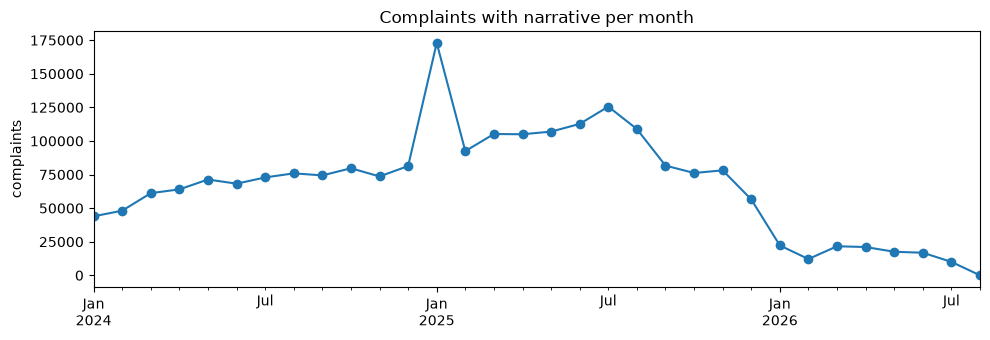

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.5))
df.groupby("month").size().plot(ax=ax, marker="o", title="Complaints with narrative per month")
ax.set_xlabel("")
ax.set_ylabel("complaints")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_volume_by_month.png", dpi=150)
plt.show()
plt.close(fig)

## Desbalance de categorías

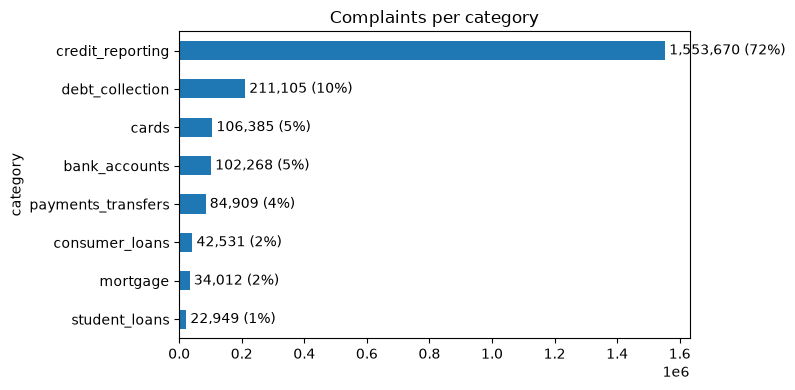

In [4]:
counts = df["category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
counts.sort_values().plot.barh(ax=ax, title="Complaints per category")
for i, v in enumerate(counts.sort_values()):
    ax.text(v, i, f" {v:,} ({v / len(df):.0%})", va="center")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_category_balance.png", dpi=150)
plt.show()
plt.close(fig)

## Mapeo producto → categoría

In [5]:
mapping_table = (
    df.groupby(["category", "product"], observed=True).size().rename("complaints").reset_index()
)
mapping_table

,category,product,complaints
0,bank_accounts,Checking or savings account,102268
1,cards,Credit card,97402
2,cards,Prepaid card,8983
3,consumer_loans,Vehicle loan or lease,25159
4,consumer_loans,"Payday loan, title loan, personal loan, or adv...",17372
5,credit_reporting,Credit reporting or other personal consumer re...,1548371
6,credit_reporting,Debt or credit management,5299
7,debt_collection,Debt collection,211105
8,mortgage,Mortgage,34012
9,payments_transfers,"Money transfer, virtual currency, or money ser...",84909


## Longitud de narrativas

count    2157829.0
mean         173.0
std          218.0
min            1.0
10%           33.0
50%          113.0
90%          357.0
99%          968.0
max         6469.0
Name: words, dtype: float64


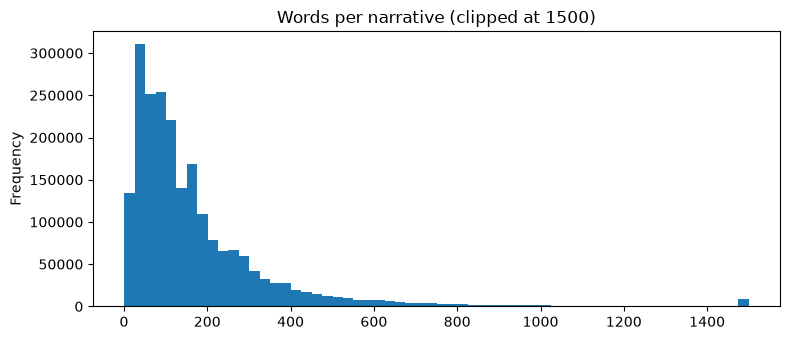

In [6]:
print(df["words"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(0))
fig, ax = plt.subplots(figsize=(8, 3.5))
df["words"].clip(upper=1500).plot.hist(
    ax=ax, bins=60, title="Words per narrative (clipped at 1500)"
)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_narrative_length.png", dpi=150)
plt.show()
plt.close(fig)

## Grupos de equidad (`Tags`)

tags
(none)                           2010986
Servicemember                      99115
Older American                     36596
Older American, Servicemember      11132
Name: count, dtype: int64


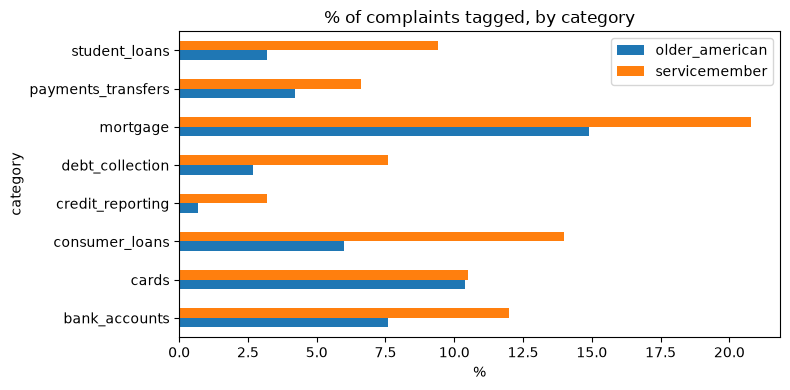

,older_american,servicemember
category,,
bank_accounts,7.6,12.0
cards,10.4,10.5
consumer_loans,6.0,14.0
credit_reporting,0.7,3.2
debt_collection,2.7,7.6
mortgage,14.9,20.8
payments_transfers,4.2,6.6
student_loans,3.2,9.4


In [7]:
tags = df["tags"].astype(str)
df["older_american"] = tags.str.contains("Older American")
df["servicemember"] = tags.str.contains("Servicemember")
print(tags.replace("", "(none)").value_counts())
by_cat = (
    df.groupby("category", observed=True)[["older_american", "servicemember"]]
    .mean()
    .mul(100)
    .round(1)
)
fig, ax = plt.subplots(figsize=(8, 4))
by_cat.plot.barh(ax=ax, title="% of complaints tagged, by category")
ax.set_xlabel("%")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_tags_by_category.png", dpi=150)
plt.show()
plt.close(fig)
by_cat

## Ejemplos por categoría (texto ya enmascarado por CFPB con XXXX)

In [8]:
example_rows = df.groupby("category", observed=True).sample(1, random_state=1)
examples = read_narratives(DATA, example_rows.index.to_numpy())
for cat, text in zip(example_rows["category"], examples, strict=True):
    print(f"--- {cat} ---\n{text[:400]}\n")

--- bank_accounts ---
Hello, i hope all is well..... Well, over the years they charge me an sustancial amount of money with their overdraft fees, they will charge thee big amount even if I made it last so all of the other little transactions were charge with the fees.please, help.this was bank of America and XXXX XXXX. Thank you and be Bless.

--- cards ---
I made a purchase for a shirt from a company called XXXX XXXX approximately four months ago, and I never received the item. I used my Chime Credit Builder Visa Card to pay for the order, which totaled {$62.00}. 

I submitted a non-receipt of goods dispute to Chime on XX/XX/year>. I provided the tracking number ( XXXX ) and explained that the package has shown as pending for months with no evidence

--- consumer_loans ---
This company has fraudulent practices. They filed twice my loan in the small claims court. The first time. I had already contacted them to get my account in order. I caught up what was due quickly. They still filed.

In [9]:
summary = {
    "rows": len(df),
    "date_min": str(df["date_received"].min().date()),
    "date_max": str(df["date_received"].max().date()),
    "categories": {str(k): int(v) for k, v in counts.items()},
    "tags": {str(k): int(v) for k, v in tags.replace("", "(none)").value_counts().items()},
}
print(json.dumps(summary, indent=2))

{
  "rows": 2157829,
  "date_min": "2024-01-01",
  "date_max": "2026-08-11",
  "categories": {
    "credit_reporting": 1553670,
    "debt_collection": 211105,
    "cards": 106385,
    "bank_accounts": 102268,
    "payments_transfers": 84909,
    "consumer_loans": 42531,
    "mortgage": 34012,
    "student_loans": 22949
  },
  "tags": {
    "(none)": 2010986,
    "Servicemember": 99115,
    "Older American": 36596,
    "Older American, Servicemember": 11132
  }
}
